# Carbon-Aware Cloud Workload Scheduling Using the DE-LU Dataset

This notebook implements a reproducible **temporal carbon-aware scheduling experiment** using the supplied `DE-LU2_generation_with_estimated_carbon_intensity.csv` dataset. It creates synthetic cloud jobs, compares an earliest-feasible carbon-unaware baseline with carbon-aware schedules, and evaluates savings across multiple days and workload profiles.

## Workflow

1. Load, inspect, and clean the 15-minute carbon-intensity series.
2. Select complete days and visualize the carbon signal.
3. Generate synthetic jobs with release times, durations, power demands, and deadlines.
4. Build a capacity-constrained earliest-feasible baseline.
5. Formulate temporal optimization as a mixed-integer linear program (MILP).
6. Compare the baseline, a simple forecast-informed policy, and a perfect-foresight oracle.
7. Evaluate emissions, energy, delay, capacity, and SLA compliance.
8. Repeat across multiple days and workload seeds; run a capacity sensitivity analysis.
9. Export schedules and experiment results to CSV.

## Interpretation and assumptions

- The grid input is the dataset column `Estimated carbon intensity (gCO2eq/kWh)`. It is an estimated lifecycle-based average intensity signal, not a direct measurement of the marginal emissions caused by an incremental task.
- The CSV has one row per production type per interval. The same interval-level carbon-intensity value is repeated across those rows; this notebook deduplicates the interval labels before scheduling.
- Each scheduling slot is 15 minutes. Job power is assumed constant while a job runs; jobs are non-preemptive and execute continuously once started.
- Jobs are synthetic because the electricity dataset contains no cloud-job telemetry.
- The baseline and optimizer use the same release times, deadlines, power budget, concurrency limit, and task durations. The optimizer cannot run every job simultaneously if the capacity constraints would be exceeded.
- **Retrospective oracle:** uses the observed carbon-intensity trace for the day being evaluated. It is an upper-bound benchmark, not a deployable policy, because it assumes perfect knowledge of the day's future intensity.
- **Forecast-informed policy:** uses the preceding day's same-slot intensity as a simple persistence forecast, then evaluates its schedule against the current day's observed intensity. This is a forecast-error demonstration, not a trained production forecast model.
- Dates affected by daylight-saving transitions and days with incomplete carbon data are excluded from the main 24-hour cross-day experiment. The cleaning step keeps source order, which is important where local timestamps repeat or jump at daylight-saving transitions.

The model estimates workload emissions as `power (kW) × slot duration (h) × carbon intensity (gCO2eq/kWh)`, summed over active slots and converted from grams to kilograms. It does **not** use the dataset's `Estimated total emissions` as if they were cloud-job emissions.

## 0. Environment setup

Required packages: `pandas`, `numpy`, `matplotlib`, and `scipy` with `scipy.optimize.milp` support (SciPy 1.9 or later). If they are missing in your Jupyter environment, install them in a separate cell with:

```python
%pip install pandas numpy matplotlib "scipy>=1.9"
```

The notebook does not install packages automatically.

In [204]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import milp, Bounds, LinearConstraint
from scipy.sparse import coo_matrix

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

SLOT_HOURS = 0.25
SLOTS_PER_HOUR = int(round(1 / SLOT_HOURS))
INTERVAL_COL = "MTU (CET/CEST)"
CI_COL = "Estimated carbon intensity (gCO2eq/kWh)"
DATA_FILENAME = "../../data/DE-LU_generation_with_estimated_carbon_intensity.csv"

# Main experiment settings. Change these to explore other workload assumptions.
P_MAX_KW = 22.0
MAX_CONCURRENT_JOBS = 4
N_JOBS = 12
BASE_SEED = 42
N_DAYS_EVALUATION = 7
WORKLOAD_SEEDS = [41, 42, 43]

P_MAX_KW = 500.0
MAX_CONCURRENT_JOBS = 60
N_JOBS = 200
BASE_SEED = 42
N_DAYS_EVALUATION = 14
WORKLOAD_SEEDS = [41, 42, 43]

print("Core settings")
print(f"Slot duration: {SLOT_HOURS:.2f} hours ({SLOT_HOURS * 60:.0f} minutes)")
print(f"Power cap: {P_MAX_KW:.1f} kW | Concurrent-job cap: {MAX_CONCURRENT_JOBS}")
print(f"Synthetic workload: {N_JOBS} jobs | Workload seeds: {WORKLOAD_SEEDS}")

Core settings
Slot duration: 0.25 hours (15 minutes)
Power cap: 500.0 kW | Concurrent-job cap: 60
Synthetic workload: 200 jobs | Workload seeds: [41, 42, 43]


In [205]:
# Prefer a CSV next to the notebook. /mnt/data is included for this provided execution environment.
path_candidates = [
    Path(DATA_FILENAME),
    Path.cwd() / DATA_FILENAME,
    Path("/mnt/data") / DATA_FILENAME,
]
DATA_PATH = next((p.resolve() for p in path_candidates if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Put the CSV in the same folder as this notebook "
        "or change DATA_PATH to the correct file location."
    )

print(f"Loading: {DATA_PATH}")
raw = pd.read_csv(DATA_PATH, low_memory=False)

required_columns = {INTERVAL_COL, CI_COL}
missing_columns = required_columns - set(raw.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print(f"Raw rows: {len(raw):,}")
print(f"Raw columns: {len(raw.columns)}")
print(f"Unique interval labels: {raw[INTERVAL_COL].nunique():,}")
print(f"Production types: {raw['Production Type'].nunique() if 'Production Type' in raw.columns else 'not available'}")
display(raw.head(3))

Loading: C:\University25\master\_teza_master\soft\project\data\DE-LU_generation_with_estimated_carbon_intensity.csv
Raw rows: 735,840
Raw columns: 9
Unique interval labels: 35,040
Production types: 21


,MTU (CET/CEST),Area,Production Type,Generation (MW),Lifecycle emission factor (gCO2eq/kWh),Estimated emissions (tCO2eq per 15 min),Estimated carbon intensity (gCO2eq/kWh),Total generation included (MW),Estimated total emissions (tCO2eq per 15 min)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|DE-LU,Biomass,"4,210.670",230.000,242.114,225.169,"58,105.730","3,270.904"
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|DE-LU,Biomass,"4,219.440",230.000,242.618,216.161,"58,101.030","3,139.801"
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|DE-LU,Biomass,"4,204.710",230.000,241.771,208.465,"58,571.590","3,052.529"


## 1. Clean the carbon-intensity series

The source contains rows by production type, but the scheduling model needs one carbon-intensity value per interval. The group-level `first()` below selects the first non-null carbon-intensity value in each interval. We also check whether different production-type rows disagree on the interval-level intensity.

The source interval order is preserved rather than sorting only on parsed local timestamps. This avoids accidentally reordering ambiguous local times around daylight-saving transitions.

In [206]:
# Check whether intensity is consistent across production-type rows within each interval.
non_null_unique_ci = raw.groupby(INTERVAL_COL, sort=False)[CI_COL].nunique(dropna=True)
inconsistent_intervals = int((non_null_unique_ci > 1).sum())
print(f"Intervals with inconsistent non-null intensity values: {inconsistent_intervals}")
if inconsistent_intervals:
    warnings.warn("Some interval labels contain multiple carbon-intensity values; inspect the source before proceeding.")

# Keep the source interval order and attach one carbon-intensity value per interval.
intervals = raw[[INTERVAL_COL]].drop_duplicates(keep="first").reset_index(drop=True)
ci_by_interval = raw.groupby(INTERVAL_COL, sort=False)[CI_COL].first()
intervals[CI_COL] = intervals[INTERVAL_COL].map(ci_by_interval).astype(float)
intervals["interval_index"] = np.arange(len(intervals), dtype=int)

# Extract the local start label while ignoring a possible '(CET)'/'(CEST)' suffix.
intervals["start_text"] = intervals[INTERVAL_COL].str.extract(
    r"^(\d{2}/\d{2}/\d{4} \d{2}:\d{2}:\d{2})", expand=False
)
intervals["start_local"] = pd.to_datetime(
    intervals["start_text"], format="%d/%m/%Y %H:%M:%S", errors="coerce"
)
if intervals["start_local"].isna().any():
    raise ValueError("Some interval start labels could not be parsed. Inspect the MTU column format.")

intervals["date"] = intervals["start_local"].dt.strftime("%Y-%m-%d")
intervals["clock"] = intervals["start_local"].dt.strftime("%H:%M")

print(f"Unique scheduling intervals: {len(intervals):,}")
print(f"Intervals with valid intensity: {intervals[CI_COL].notna().sum():,}")
print(f"Intervals with missing intensity: {intervals[CI_COL].isna().sum():,}")
print(f"Intensity range: {intervals[CI_COL].min():.2f}–{intervals[CI_COL].max():.2f} gCO2eq/kWh")
display(intervals[["interval_index", INTERVAL_COL, "start_local", CI_COL]].head(5))

Intervals with inconsistent non-null intensity values: 0
Unique scheduling intervals: 35,040
Intervals with valid intensity: 27,130
Intervals with missing intensity: 7,910
Intensity range: 79.73–598.04 gCO2eq/kWh


,interval_index,MTU (CET/CEST),start_local,Estimated carbon intensity (gCO2eq/kWh)
0,0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,2026-01-01 00:00:00,225.169
1,1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,2026-01-01 00:15:00,216.161
2,2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,2026-01-01 00:30:00,208.465
3,3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,2026-01-01 00:45:00,203.032
4,4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,2026-01-01 01:00:00,194.782


In [207]:
# Daily coverage diagnostics. A complete 24-hour day has 96 quarter-hour slots and no missing CI values.
day_stats = (
    intervals.groupby("date", sort=False)
    .agg(
        n_slots=("interval_index", "size"),
        valid_ci_slots=(CI_COL, "count"),
        mean_ci_g_per_kwh=(CI_COL, "mean"),
        min_ci_g_per_kwh=(CI_COL, "min"),
        max_ci_g_per_kwh=(CI_COL, "max"),
    )
    .reset_index()
    .sort_values("date")
    .reset_index(drop=True)
)
day_stats["complete_96_slot_day"] = (day_stats["n_slots"] == 96) & (day_stats["valid_ci_slots"] == 96)
complete_days = day_stats.loc[day_stats["complete_96_slot_day"], "date"].tolist()

print(f"Calendar dates represented: {len(day_stats):,}")
print(f"Complete 96-slot days with valid intensity: {len(complete_days):,}")
if not complete_days:
    raise ValueError("No complete 96-slot days with valid carbon intensity were found.")

last_valid_row = intervals.loc[intervals[CI_COL].notna()].iloc[-1]
print(f"Last valid interval label: {last_valid_row[INTERVAL_COL]}")
print("Recent daily coverage:")
display(day_stats.tail(12))

# Use the latest complete standard 24-hour day for the detailed worked example.
DEMO_DATE = complete_days[-2]
print(f"Detailed demonstration date: {DEMO_DATE}")
print("Note: partial days and 92/100-slot daylight-saving transition days are excluded from the primary evaluation.")

Calendar dates represented: 365
Complete 96-slot days with valid intensity: 281
Last valid interval label: 10/10/2026 15:15:00 - 10/10/2026 15:30:00
Recent daily coverage:


,date,n_slots,valid_ci_slots,mean_ci_g_per_kwh,min_ci_g_per_kwh,max_ci_g_per_kwh,complete_96_slot_day
353,2026-12-20,96,0,NaN,NaN,NaN,False
354,2026-12-21,96,0,NaN,NaN,NaN,False
355,2026-12-22,96,0,NaN,NaN,NaN,False
356,2026-12-23,96,0,NaN,NaN,NaN,False
357,2026-12-24,96,0,NaN,NaN,NaN,False
358,2026-12-25,96,0,NaN,NaN,NaN,False
359,2026-12-26,96,0,NaN,NaN,NaN,False
360,2026-12-27,96,0,NaN,NaN,NaN,False
361,2026-12-28,96,0,NaN,NaN,NaN,False
362,2026-12-29,96,0,NaN,NaN,NaN,False


Detailed demonstration date: 2026-10-08
Note: partial days and 92/100-slot daylight-saving transition days are excluded from the primary evaluation.


## 2. Visualize the selected day's carbon signal

The chart uses slot position (elapsed quarter-hour index) on the x-axis. This is intentional: using the original local-clock labels directly can make daylight-saving transitions appear as duplicate or missing time intervals.

C:\Users\user\AppData\Local\Temp\ipykernel_10244\3870921684.py:21: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


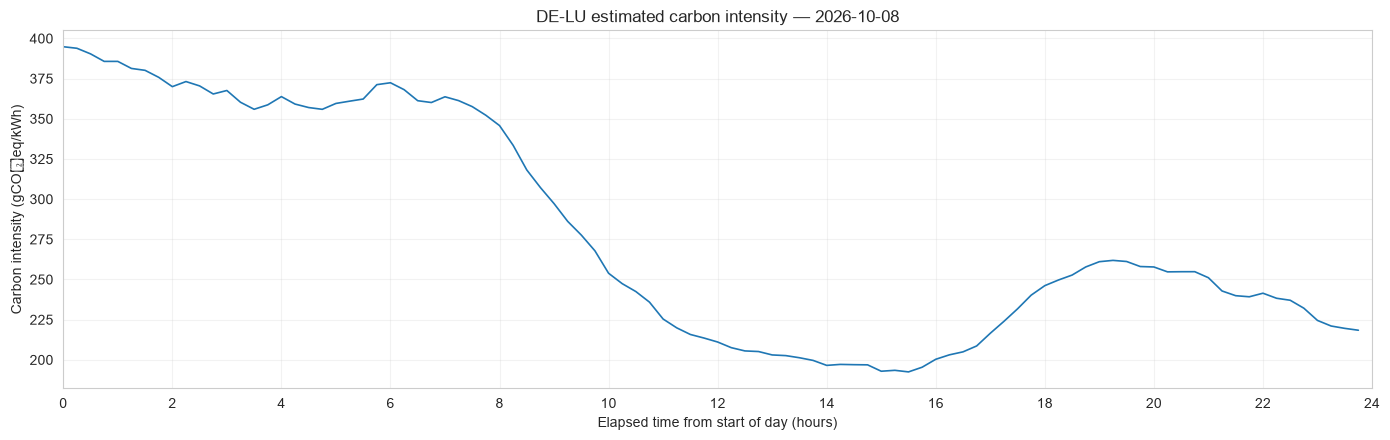

       gCO2eq/kWh
count      96.000
mean      280.074
std        69.366
min       192.482
25%       219.285
50%       254.782
75%       359.695
max       394.846


In [208]:
def get_day_frame(date_string: str) -> pd.DataFrame:
    """Return a date's interval rows in original source order."""
    frame = intervals.loc[intervals["date"] == date_string].copy().reset_index(drop=True)
    return frame


demo_day = get_day_frame(DEMO_DATE)
demo_ci = demo_day[CI_COL].to_numpy(dtype=float)
if len(demo_day) != 96 or not np.isfinite(demo_ci).all():
    raise ValueError(f"Demo date {DEMO_DATE} is not a complete 96-slot day.")

slot_hours = np.arange(len(demo_day)) * SLOT_HOURS
plt.figure(figsize=(14, 4.5))
plt.plot(slot_hours, demo_ci, linewidth=1.2)
plt.title(f"DE-LU estimated carbon intensity — {DEMO_DATE}")
plt.xlabel("Elapsed time from start of day (hours)")
plt.ylabel("Carbon intensity (gCO₂eq/kWh)")
plt.xticks(np.arange(0, 24.1, 2))
plt.xlim(0, 24)
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

print(pd.Series(demo_ci, name="gCO2eq/kWh").describe().to_frame())

## 3. Generate a flexible synthetic workload

Each job has a release slot, duration, power demand, and completion deadline. Durations are multiples of 15 minutes. The jobs are non-preemptive: when started, a job occupies its power demand for every slot until it finishes.

The workload generator is deterministic for a given random seed. Use the same generated workload when comparing policies so that changes in emissions are attributable to scheduling decisions rather than different tasks.

In [209]:
import numpy as np
import pandas as pd


def generate_workload(
    n_slots: int,
    n_jobs: int = N_JOBS,
    seed: int = BASE_SEED,
    p_max_kw: float = P_MAX_KW,
    max_concurrent_jobs: int = MAX_CONCURRENT_JOBS,
) -> pd.DataFrame:
    """
    Generate synthetic jobs with a guaranteed feasible reference schedule.

    Jobs are assigned to concurrency lanes. Each lane executes jobs
    sequentially, so jobs in the same lane cannot overlap.
    """

    if n_slots < 1:
        raise ValueError("n_slots must be positive.")
    if n_jobs < 1:
        raise ValueError("n_jobs must be positive.")
    if p_max_kw < 3:
        raise ValueError("p_max_kw must be at least 3 kW.")
    if max_concurrent_jobs < 1:
        raise ValueError("max_concurrent_jobs must be positive.")

    rng = np.random.default_rng(seed)

    durations = rng.choice(
        [4, 8, 12, 16],
        size=n_jobs,
        p=[0.25, 0.35, 0.25, 0.15],
    ).astype(int)

    powers = rng.choice(
        [3, 4, 5, 6, 7, 8],
        size=n_jobs,
        p=[0.10, 0.15, 0.20, 0.25, 0.20, 0.10],
    ).astype(float)

    # Ensure each task individually fits the power budget.
    powers = np.minimum(powers, p_max_kw)

    # Build a feasible schedule using independent execution lanes.
    # A lane is a logical slot for sequentially executed jobs.
    lane_end = np.zeros(max_concurrent_jobs, dtype=int)
    reference_starts = np.zeros(n_jobs, dtype=int)
    reference_ends = np.zeros(n_jobs, dtype=int)

    # Long jobs first improves packing across lanes.
    order = np.argsort(-durations)

    for i in order:
        duration = int(durations[i])

        lane = int(np.argmin(lane_end))
        start = int(lane_end[lane])
        end = start + duration

        if end > n_slots:
            raise ValueError(
                f"{n_jobs} jobs cannot fit into {n_slots} slots using "
                f"{max_concurrent_jobs} lanes. Reduce n_jobs or "
                "durations, increase the horizon, or increase concurrency."
            )

        reference_starts[i] = start
        reference_ends[i] = end
        lane_end[lane] = end

    # Create release times and deadlines around the reference schedule.
    # Release times are no later than the reference start.
    release_slots = np.zeros(n_jobs, dtype=int)
    deadline_slots = np.zeros(n_jobs, dtype=int)

    for i in range(n_jobs):
        release_slots[i] = reference_starts[i]

        slack = int(rng.integers(16, 37))
        deadline_slots[i] = min(
            n_slots,
            reference_ends[i] + slack,
        )

    tasks = pd.DataFrame({
        "task_id": [f"J{i + 1:02d}" for i in range(n_jobs)],
        "release_slot": release_slots,
        "duration_slots": durations,
        "duration_hours": durations * SLOT_HOURS,
        "power_kw": powers,
        "deadline_slot": deadline_slots,
        "reference_start_slot": reference_starts,
        "reference_end_slot": reference_ends,
    })

    tasks = tasks.sort_values(
        ["release_slot", "task_id"]
    ).reset_index(drop=True)

    return tasks


def slot_to_clock(slot: int) -> str:
    """Format a slot index as HH:MM; slot 96 is 24:00."""
    minutes = int(slot) * 15
    return f"{minutes // 60:02d}:{minutes % 60:02d}"


tasks = generate_workload(
    n_slots=len(demo_day),
    n_jobs=N_JOBS,
    seed=BASE_SEED,
    p_max_kw=26.0,
    max_concurrent_jobs=MAX_CONCURRENT_JOBS,
)

workload_display = tasks.copy()
workload_display["release_time"] = (
    workload_display["release_slot"].map(slot_to_clock)
)
workload_display["deadline_time"] = (
    workload_display["deadline_slot"].map(slot_to_clock)
)

display(
    workload_display[
        [
            "task_id",
            "release_time",
            "duration_hours",
            "power_kw",
            "deadline_time",
        ]
    ]
)

,task_id,release_time,duration_hours,power_kw,deadline_time
0,J03,00:00,4.000,6.000,10:30
1,J04,00:00,3.000,4.000,11:45
2,J06,00:00,4.000,4.000,12:00
3,J08,00:00,3.000,6.000,07:30
4,J100,00:00,4.000,6.000,11:00
...,...,...,...,...,...
195,J192,07:00,1.000,4.000,14:45
196,J193,07:00,1.000,6.000,13:00
197,J195,07:00,1.000,3.000,14:45
198,J196,07:00,1.000,6.000,15:15


## 4. Carbon-unaware baseline: earliest feasible execution

The baseline is an FCFS-like policy: jobs are considered by release time and task ID, and each starts at its earliest slot that satisfies the power budget, concurrency limit, release time, and deadline. It is **not** an unconstrained “run everything immediately” baseline; the same physical and SLA constraints apply to every policy.

In [210]:
def schedule_earliest_feasible(
    tasks: pd.DataFrame,
    n_slots: int,
    p_max_kw: float,
    max_concurrent_jobs: int | None,
) -> dict[str, int]:
    """Schedule each job at its earliest feasible start, respecting power/concurrency and deadlines."""
    power_load = np.zeros(n_slots, dtype=float)
    job_load = np.zeros(n_slots, dtype=int)
    starts: dict[str, int] = {}

    ordered = tasks.sort_values(["release_slot", "task_id"])
    for row in ordered.itertuples(index=False):
        earliest = int(row.release_slot)
        duration = int(row.duration_slots)
        latest_start = int(row.deadline_slot) - duration
        chosen = None

        for start in range(earliest, latest_start + 1):
            end = start + duration
            if end > n_slots:
                continue
            power_ok = np.all(power_load[start:end] + float(row.power_kw) <= p_max_kw + 1e-9)
            concurrency_ok = (
                True if max_concurrent_jobs is None
                else np.all(job_load[start:end] + 1 <= max_concurrent_jobs)
            )
            if power_ok and concurrency_ok:
                chosen = start
                break

        if chosen is None:
            raise ValueError(
                f"The earliest-feasible baseline could not schedule {row.task_id} within its deadline. "
                "Try reducing the workload or increasing capacity."
            )

        end = chosen + duration
        power_load[chosen:end] += float(row.power_kw)
        job_load[chosen:end] += 1
        starts[str(row.task_id)] = int(chosen)

    return starts


baseline_starts = schedule_earliest_feasible(
    tasks, len(demo_day), P_MAX_KW, MAX_CONCURRENT_JOBS
)
print(f"Baseline scheduled {len(baseline_starts)} of {len(tasks)} jobs.")

Baseline scheduled 200 of 200 jobs.


## 5. Temporal optimization using a MILP

For each job, the model creates a binary decision variable for every feasible start slot. Exactly one start slot must be selected per job. The objective minimizes estimated emissions using the supplied carbon-intensity profile:

\[
\min E_{kg}=\frac{1}{1000}\sum_t CI_t\,\Delta t\sum_i P_i z_{i,t}
\]

where `CI` is in gCO₂eq/kWh, `P` is in kW, and `Δt = 0.25 h`. The constraints ensure that every job starts after release, finishes by its deadline, and respects both the aggregate power capacity and the maximum concurrent-job count in every slot.

The function accepts an objective carbon-intensity profile. That lets the same optimizer run in oracle mode (today's observed profile) or forecast-informed mode (a forecast proxy), while evaluation always uses the observed current-day profile.

**Runtime note:** the solver uses a 5-second time limit per solve and a 1% relative MIP gap target. If it stops before proving optimality but returns an integer-feasible incumbent, the notebook uses that incumbent and validates its resource/SLA constraints. Tighten the gap or increase the limit for smaller studies where exact optimality is needed.

In [211]:
def optimize_schedule_milp(
    tasks: pd.DataFrame,
    objective_ci: np.ndarray,
    p_max_kw: float,
    max_concurrent_jobs: int | None,
    time_limit_seconds: int = 60,
) -> dict[str, int]:
    """Minimize emissions over feasible non-preemptive task start times using SciPy/HiGHS MILP."""
    ci = np.asarray(objective_ci, dtype=float)
    n_slots = len(ci)
    job_table = tasks.reset_index(drop=True).copy()
    n_jobs = len(job_table)

    if n_slots == 0 or not np.isfinite(ci).any():
        raise ValueError("The objective carbon-intensity profile is empty or entirely missing.")

    # A binary variable represents one possible start for one job: (job_index, start, end).
    candidates: list[tuple[int, int, int]] = []
    objective: list[float] = []
    for j, row in job_table.iterrows():
        duration = int(row["duration_slots"])
        earliest = int(row["release_slot"])
        latest_start = int(row["deadline_slot"]) - duration
        feasible_count = 0
        for start in range(earliest, latest_start + 1):
            end = start + duration
            if end > n_slots:
                continue
            interval_ci = ci[start:end]
            # Never schedule a job across a missing carbon-intensity observation.
            if not np.isfinite(interval_ci).all():
                continue
            candidates.append((j, start, end))
            energy_kwh = float(row["power_kw"]) * duration * SLOT_HOURS
            emissions_kg = float(row["power_kw"]) * SLOT_HOURS * float(interval_ci.sum()) / 1000.0
            objective.append(emissions_kg)
            feasible_count += 1
        if feasible_count == 0:
            raise ValueError(f"No carbon-data-valid start window exists for task {row['task_id']}.")

    n_vars = len(candidates)
    if n_vars == 0:
        raise ValueError("No feasible task start variables were generated.")

    # Constraint rows: one equality per job, one power cap per slot, optional concurrency cap per slot.
    n_power_rows = n_slots
    n_concurrency_rows = n_slots if max_concurrent_jobs is not None else 0
    n_constraints = n_jobs + n_power_rows + n_concurrency_rows
    row_indices: list[int] = []
    col_indices: list[int] = []
    values: list[float] = []

    for k, (j, start, end) in enumerate(candidates):
        row_indices.append(j)
        col_indices.append(k)
        values.append(1.0)
        power_kw = float(job_table.iloc[j]["power_kw"])
        for slot in range(start, end):
            row_indices.append(n_jobs + slot)
            col_indices.append(k)
            values.append(power_kw)
            if max_concurrent_jobs is not None:
                row_indices.append(n_jobs + n_slots + slot)
                col_indices.append(k)
                values.append(1.0)

    A = coo_matrix(
        (values, (row_indices, col_indices)),
        shape=(n_constraints, n_vars),
        dtype=float,
    ).tocsr()

    lower = np.zeros(n_constraints, dtype=float)
    upper = np.zeros(n_constraints, dtype=float)
    lower[:n_jobs] = 1.0
    upper[:n_jobs] = 1.0
    upper[n_jobs:n_jobs + n_slots] = float(p_max_kw)
    if max_concurrent_jobs is not None:
        upper[n_jobs + n_slots:] = int(max_concurrent_jobs)

    result = milp(
        c=np.asarray(objective, dtype=float),
        integrality=np.ones(n_vars, dtype=np.int8),
        bounds=Bounds(np.zeros(n_vars), np.ones(n_vars)),
        constraints=LinearConstraint(A, lower, upper),
        options={"time_limit": time_limit_seconds, "mip_rel_gap": 0.01},
    )
    if result.x is None:
        raise RuntimeError(f"MILP solver did not find a feasible incumbent: {result.message}")
    if not result.success:
        warnings.warn(
            f"MILP stopped before proving optimality (status={result.status}: {result.message}); "
            "using the feasible incumbent. Check solver gap/time limits for this run."
        )

    selected = np.flatnonzero(result.x > 0.5)
    if len(selected) != n_jobs:
        raise AssertionError(f"Expected {n_jobs} selected task starts, but found {len(selected)}.")

    starts: dict[str, int] = {}
    for k in selected:
        job_index, start, _ = candidates[int(k)]
        starts[str(job_table.iloc[job_index]["task_id"])] = int(start)
    return starts


# Oracle schedule: uses the observed carbon-intensity trace for the demonstration day.
oracle_starts = optimize_schedule_milp(
    tasks, demo_ci, P_MAX_KW, MAX_CONCURRENT_JOBS
)
print(f"MILP found a feasible schedule for {len(oracle_starts)} jobs.")

MILP found a feasible schedule for 200 jobs.


## 6. Metrics and schedule validation

For every policy, compute workload energy, estimated workload emissions, emissions savings relative to baseline, average and maximum start delay, deadline violations, peak power, peak concurrency, and average intensity weighted by workload energy. With fixed task powers and durations, total workload energy should be identical for all feasible policies; emissions change because the jobs are placed in different carbon-intensity intervals.

In [212]:
def evaluate_schedule(
    tasks: pd.DataFrame,
    starts: dict[str, int],
    actual_ci: np.ndarray,
    p_max_kw: float,
    max_concurrent_jobs: int | None,
) -> tuple[dict, pd.DataFrame, np.ndarray, np.ndarray]:
    """Evaluate a schedule against the observed CI trace and return metrics plus slot loads."""
    ci = np.asarray(actual_ci, dtype=float)
    n_slots = len(ci)
    power_load = np.zeros(n_slots, dtype=float)
    job_load = np.zeros(n_slots, dtype=int)
    schedule_rows = []
    total_energy_kwh = 0.0
    total_emissions_kg = 0.0
    deadline_violations = 0
    release_violations = 0

    task_lookup = tasks.set_index("task_id")
    for task_id, start_value in starts.items():
        row = task_lookup.loc[task_id]
        start = int(start_value)
        duration = int(row["duration_slots"])
        end = start + duration
        power = float(row["power_kw"])
        if start < 0 or end > n_slots:
            raise AssertionError(f"Task {task_id} lies outside the scheduling horizon.")
        if not np.isfinite(ci[start:end]).all():
            raise AssertionError(f"Task {task_id} overlaps missing carbon-intensity data.")

        energy_kwh = power * duration * SLOT_HOURS
        emissions_kg = power * SLOT_HOURS * float(ci[start:end].sum()) / 1000.0
        total_energy_kwh += energy_kwh
        total_emissions_kg += emissions_kg
        power_load[start:end] += power
        job_load[start:end] += 1

        if start < int(row["release_slot"]):
            release_violations += 1
        if end > int(row["deadline_slot"]):
            deadline_violations += 1

        schedule_rows.append({
            "task_id": task_id,
            "release_slot": int(row["release_slot"]),
            "start_slot": start,
            "end_slot": end,
            "duration_slots": duration,
            "duration_hours": duration * SLOT_HOURS,
            "power_kw": power,
            "deadline_slot": int(row["deadline_slot"]),
            "waiting_hours": (start - int(row["release_slot"])) * SLOT_HOURS,
            "deadline_slack_hours": (int(row["deadline_slot"]) - end) * SLOT_HOURS,
            "energy_kwh": energy_kwh,
            "emissions_kgCO2eq": emissions_kg,
        })

    peak_power = float(power_load.max(initial=0.0))
    peak_jobs = int(job_load.max(initial=0))
    power_violation_slots = int(np.sum(power_load > p_max_kw + 1e-8))
    concurrency_violation_slots = (
        0 if max_concurrent_jobs is None
        else int(np.sum(job_load > max_concurrent_jobs))
    )
    weighted_ci = (total_emissions_kg * 1000.0 / total_energy_kwh) if total_energy_kwh else np.nan
    available_capacity_kwh = p_max_kw * n_slots * SLOT_HOURS

    metrics = {
        "energy_kwh": total_energy_kwh,
        "emissions_kgCO2eq": total_emissions_kg,
        "weighted_CI_gCO2eq_per_kWh": weighted_ci,
        "mean_wait_hours": float(np.mean([r["waiting_hours"] for r in schedule_rows])) if schedule_rows else 0.0,
        "max_wait_hours": float(np.max([r["waiting_hours"] for r in schedule_rows])) if schedule_rows else 0.0,
        "deadline_violations": deadline_violations,
        "release_violations": release_violations,
        "peak_power_kw": peak_power,
        "peak_concurrent_jobs": peak_jobs,
        "power_violation_slots": power_violation_slots,
        "concurrency_violation_slots": concurrency_violation_slots,
        "capacity_energy_utilization_pct": 100.0 * total_energy_kwh / available_capacity_kwh if available_capacity_kwh else np.nan,
    }
    schedule_table = pd.DataFrame(schedule_rows).sort_values(["start_slot", "task_id"]).reset_index(drop=True)

    violations = [
        metrics["deadline_violations"], metrics["release_violations"],
        metrics["power_violation_slots"], metrics["concurrency_violation_slots"],
    ]
    if any(violations):
        raise AssertionError(f"Schedule validation failed. Violation counts: {violations}")
    return metrics, schedule_table, power_load, job_load


def add_clock_labels(schedule_table: pd.DataFrame) -> pd.DataFrame:
    out = schedule_table.copy()
    for col in ["release_slot", "start_slot", "end_slot", "deadline_slot"]:
        out[col.replace("_slot", "_time")] = out[col].map(slot_to_clock)
    cols = [
        "task_id", "release_time", "start_time", "end_time", "deadline_time",
        "duration_hours", "power_kw", "waiting_hours", "deadline_slack_hours",
        "energy_kwh", "emissions_kgCO2eq",
    ]
    return out[cols]


def load_profile(tasks: pd.DataFrame, starts: dict[str, int], n_slots: int) -> np.ndarray:
    load = np.zeros(n_slots, dtype=float)
    task_lookup = tasks.set_index("task_id")
    for task_id, start in starts.items():
        row = task_lookup.loc[task_id]
        end = int(start) + int(row["duration_slots"])
        load[int(start):end] += float(row["power_kw"])
    return load

# Validate baseline and oracle and confirm that task energy is invariant to scheduling policy.
base_metrics, base_schedule, base_power, base_jobs = evaluate_schedule(
    tasks, baseline_starts, demo_ci, P_MAX_KW, MAX_CONCURRENT_JOBS
)
oracle_metrics, oracle_schedule, oracle_power, oracle_jobs = evaluate_schedule(
    tasks, oracle_starts, demo_ci, P_MAX_KW, MAX_CONCURRENT_JOBS
)
assert np.isclose(base_metrics["energy_kwh"], oracle_metrics["energy_kwh"])
print("Baseline and oracle pass release, deadline, power, and concurrency validation.")

Baseline and oracle pass release, deadline, power, and concurrency validation.


## 7. Add a forecast-informed policy

For a practical comparison without a separate forecast dataset, use the preceding calendar day's carbon-intensity trace as a same-slot persistence forecast. Optimize the schedule against that forecast, but compute the resulting emissions using the actual current-day carbon intensities. The forecast policy may outperform or underperform the baseline, depending on how well the preceding day predicts the current day.

In [213]:
def get_complete_day_ci(date_string: str) -> np.ndarray:
    day = get_day_frame(date_string)
    values = day[CI_COL].to_numpy(dtype=float)
    if len(values) != 96 or not np.isfinite(values).all():
        raise ValueError(f"{date_string} is not a complete 96-slot day with valid CI values.")
    return values


def previous_calendar_day(date_string: str) -> str:
    return (pd.Timestamp(date_string) - pd.Timedelta(days=1)).strftime("%Y-%m-%d")


forecast_date = previous_calendar_day(DEMO_DATE)
forecast_ci = get_complete_day_ci(forecast_date)
forecast_starts = optimize_schedule_milp(
    tasks, forecast_ci, P_MAX_KW, MAX_CONCURRENT_JOBS
)

policies = {
    "Carbon-unaware baseline": baseline_starts,
    "Previous-day forecast": forecast_starts,
    "Retrospective oracle": oracle_starts,
}

policy_metrics = {}
policy_schedules = {}
policy_loads = {}
for policy_name, policy_starts in policies.items():
    metrics, schedule_table, power_load, job_load = evaluate_schedule(
        tasks, policy_starts, demo_ci, P_MAX_KW, MAX_CONCURRENT_JOBS
    )
    policy_metrics[policy_name] = metrics
    policy_schedules[policy_name] = schedule_table
    policy_loads[policy_name] = power_load

baseline_emissions = policy_metrics["Carbon-unaware baseline"]["emissions_kgCO2eq"]
comparison_rows = []
for policy_name, metrics in policy_metrics.items():
    saving_kg = baseline_emissions - metrics["emissions_kgCO2eq"]
    saving_pct = 100.0 * saving_kg / baseline_emissions if baseline_emissions else np.nan
    comparison_rows.append({
        "policy": policy_name,
        **metrics,
        "emissions_savings_vs_baseline_kg": saving_kg,
        "emissions_savings_vs_baseline_pct": saving_pct,
    })
demo_metrics = pd.DataFrame(comparison_rows).set_index("policy")

print(f"Forecast proxy: previous day's profile ({forecast_date}); emissions evaluated on {DEMO_DATE}.")
display(demo_metrics[[
    "energy_kwh", "emissions_kgCO2eq", "emissions_savings_vs_baseline_kg",
    "emissions_savings_vs_baseline_pct", "weighted_CI_gCO2eq_per_kWh",
    "mean_wait_hours", "max_wait_hours", "peak_power_kw", "peak_concurrent_jobs",
    "deadline_violations", "power_violation_slots", "concurrency_violation_slots",
]])

print("\nForecast-policy schedule:")
display(add_clock_labels(policy_schedules["Previous-day forecast"]))
print("\nOracle schedule:")
display(add_clock_labels(policy_schedules["Retrospective oracle"]))

Forecast proxy: previous day's profile (2026-10-07); emissions evaluated on 2026-10-08.


,energy_kwh,emissions_kgCO2eq,emissions_savings_vs_baseline_kg,emissions_savings_vs_baseline_pct,weighted_CI_gCO2eq_per_kWh,mean_wait_hours,max_wait_hours,peak_power_kw,peak_concurrent_jobs,deadline_violations,power_violation_slots,concurrency_violation_slots
policy,,,,,,,,,,,,
Carbon-unaware baseline,"2,529.000",933.241,0.000,0.000,369.016,0.000,0.000,356.000,60,0,0,0
Previous-day forecast,"2,529.000",680.059,253.182,27.129,268.904,6.136,9.000,365.000,60,0,0,0
Retrospective oracle,"2,529.000",678.303,254.938,27.317,268.210,6.247,9.000,365.000,60,0,0,0



Forecast-policy schedule:


,task_id,release_time,start_time,end_time,deadline_time,duration_hours,power_kw,waiting_hours,deadline_slack_hours,energy_kwh,emissions_kgCO2eq
0,J101,00:00,04:00,08:00,08:00,4.000,7.000,4.000,0.000,28.000,10.126
1,J102,00:00,04:00,07:00,07:00,3.000,4.000,4.000,0.000,12.000,4.352
2,J170,00:00,04:00,08:00,08:00,4.000,7.000,4.000,0.000,28.000,10.126
3,J21,00:00,04:00,07:00,07:00,3.000,5.000,4.000,0.000,15.000,5.440
4,J30,00:00,04:00,07:00,07:00,3.000,4.000,4.000,0.000,12.000,4.352
...,...,...,...,...,...,...,...,...,...,...,...
195,J163,07:00,13:15,14:15,16:15,1.000,4.000,6.250,2.000,4.000,0.800
196,J192,07:00,13:15,14:15,14:45,1.000,4.000,6.250,0.500,4.000,0.800
197,J195,07:00,13:15,14:15,14:45,1.000,3.000,6.250,0.500,3.000,0.600
198,J59,06:00,13:15,14:15,14:30,1.000,3.000,7.250,0.250,3.000,0.600



Oracle schedule:


,task_id,release_time,start_time,end_time,deadline_time,duration_hours,power_kw,waiting_hours,deadline_slack_hours,energy_kwh,emissions_kgCO2eq
0,J08,00:00,02:45,05:45,07:30,3.000,6.000,2.750,1.750,18.000,6.490
1,J102,00:00,02:45,05:45,07:00,3.000,4.000,2.750,1.250,12.000,4.327
2,J14,00:00,02:45,05:45,08:15,3.000,7.000,2.750,2.500,21.000,7.571
3,J21,00:00,02:45,05:45,07:00,3.000,5.000,2.750,1.250,15.000,5.408
4,J30,00:00,02:45,05:45,07:00,3.000,4.000,2.750,1.250,12.000,4.327
...,...,...,...,...,...,...,...,...,...,...,...
195,J136,07:00,15:00,16:00,16:45,1.000,6.000,8.000,0.750,6.000,1.161
196,J155,07:00,15:00,16:00,16:00,1.000,6.000,8.000,0.000,6.000,1.161
197,J163,07:00,15:00,16:00,16:15,1.000,4.000,8.000,0.250,4.000,0.774
198,J199,07:00,15:00,16:00,17:00,1.000,6.000,8.000,1.000,6.000,1.161


## 8. Visualize schedules and aggregate power

The three panels show (1) observed and forecast carbon intensity, (2) aggregate power demand for each policy, and (3) task start times as a Gantt-style plot. The power chart makes the capacity restriction explicit; the Gantt plot helps show which jobs were shifted.

C:\Users\user\AppData\Local\Temp\ipykernel_10244\93170090.py:60: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


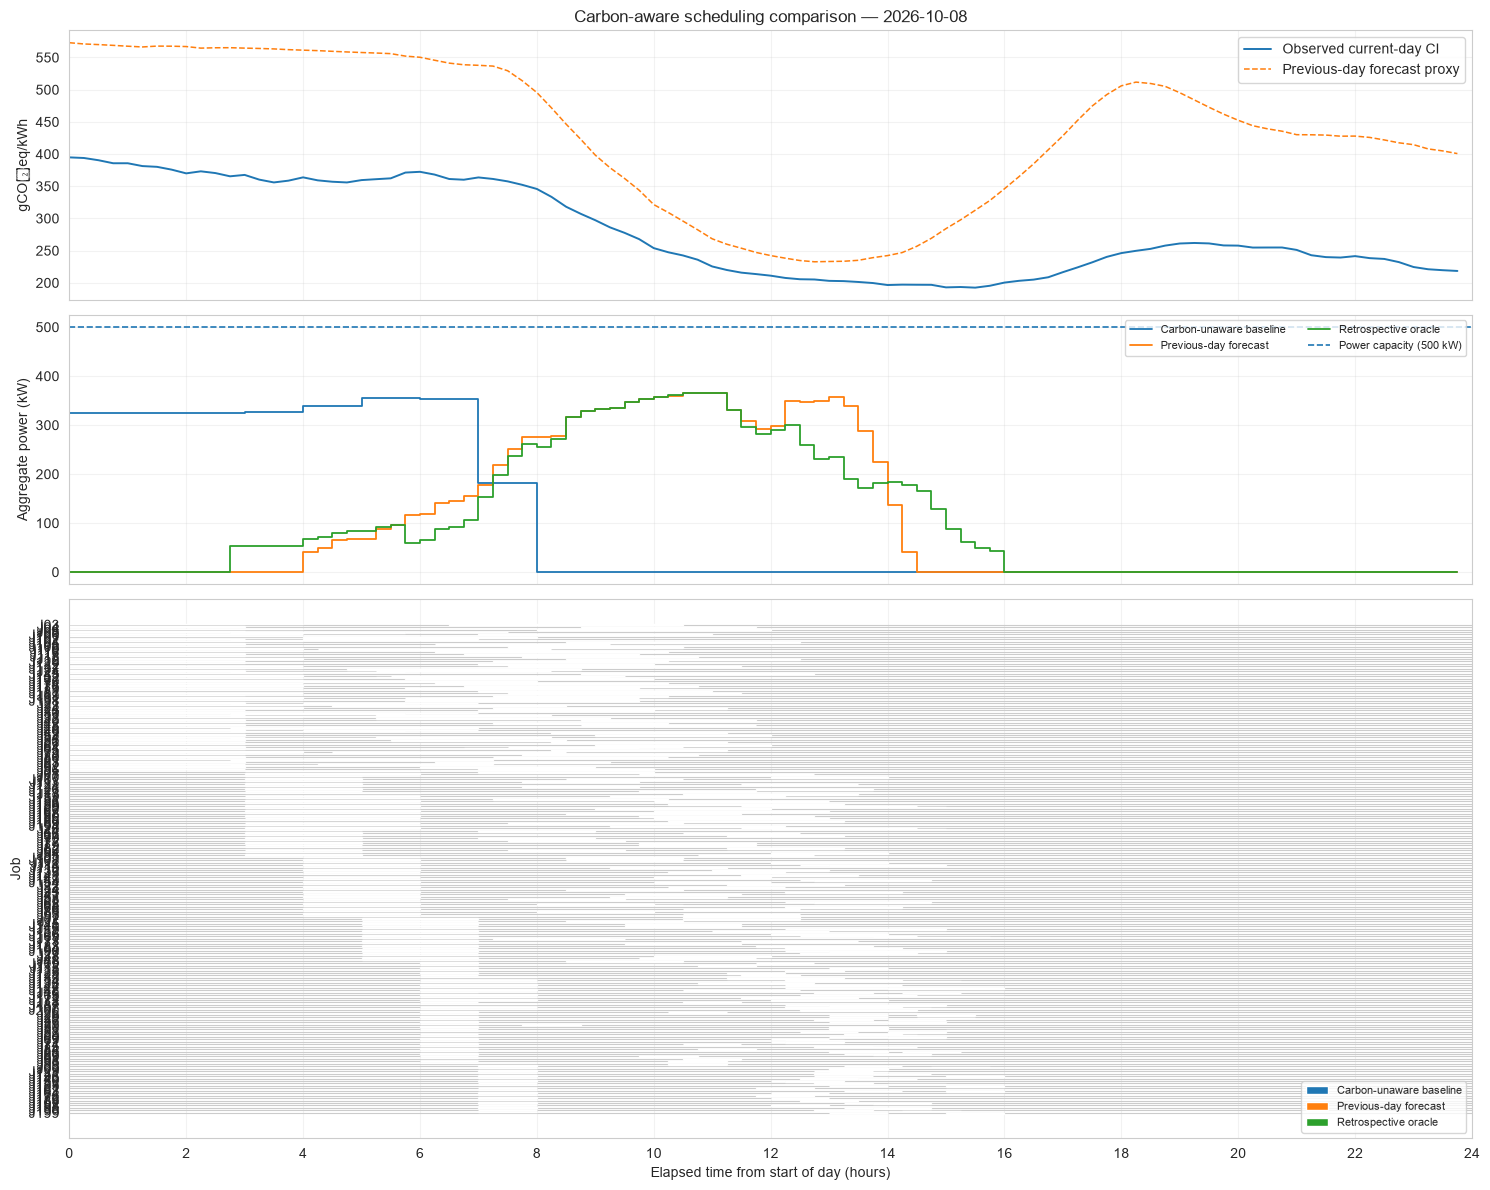

In [214]:
def plot_policy_comparison(
    date_string: str,
    tasks: pd.DataFrame,
    actual_ci: np.ndarray,
    forecast_profile: np.ndarray,
    starts_by_policy: dict[str, dict[str, int]],
    p_max_kw: float,
) -> None:
    n_slots = len(actual_ci)
    hours = np.arange(n_slots) * SLOT_HOURS
    fig, (ax_ci, ax_power, ax_gantt) = plt.subplots(
        3, 1, figsize=(15, 12), sharex=True,
        gridspec_kw={"height_ratios": [1.0, 1.0, 2.0]}
    )

    ax_ci.plot(hours, actual_ci, label="Observed current-day CI", linewidth=1.4)
    ax_ci.plot(hours, forecast_profile, label="Previous-day forecast proxy", linewidth=1.1, linestyle="--")
    ax_ci.set_ylabel("gCO₂eq/kWh")
    ax_ci.set_title(f"Carbon-aware scheduling comparison — {date_string}")
    ax_ci.legend(loc="best")
    ax_ci.grid(True, alpha=0.25)

    for policy_name, starts in starts_by_policy.items():
        power = load_profile(tasks, starts, n_slots)
        ax_power.step(hours, power, where="post", label=policy_name, linewidth=1.3)
    ax_power.axhline(p_max_kw, linestyle="--", linewidth=1.2, label=f"Power capacity ({p_max_kw:g} kW)")
    ax_power.set_ylabel("Aggregate power (kW)")
    ax_power.legend(loc="upper right", ncol=2, fontsize=8)
    ax_power.grid(True, alpha=0.25)

    base_y = np.arange(len(tasks)) * 4.0
    policy_offsets = {
        "Carbon-unaware baseline": 0.0,
        "Previous-day forecast": 1.0,
        "Retrospective oracle": 2.0,
    }
    task_lookup = tasks.set_index("task_id")
    for policy_name, starts in starts_by_policy.items():
        left = []
        widths = []
        y_values = []
        for j, task in tasks.reset_index(drop=True).iterrows():
            start = int(starts[str(task["task_id"])])
            duration_h = int(task["duration_slots"]) * SLOT_HOURS
            left.append(start * SLOT_HOURS)
            widths.append(duration_h)
            y_values.append(base_y[j] + policy_offsets[policy_name])
        ax_gantt.barh(y_values, widths, left=left, height=0.65, label=policy_name)

    ax_gantt.set_yticks(base_y + 1.0)
    ax_gantt.set_yticklabels(tasks["task_id"].tolist())
    ax_gantt.invert_yaxis()
    ax_gantt.set_ylabel("Job")
    ax_gantt.set_xlabel("Elapsed time from start of day (hours)")
    ax_gantt.set_xticks(np.arange(0, 24.1, 2))
    ax_gantt.set_xlim(0, n_slots * SLOT_HOURS)
    ax_gantt.grid(True, axis="x", alpha=0.25)
    ax_gantt.legend(loc="lower right", fontsize=8)

    plt.tight_layout()
    plt.show()


plot_policy_comparison(DEMO_DATE, tasks, demo_ci, forecast_ci, policies, P_MAX_KW)

## 9. Repeat over multiple days and workload profiles

The main multi-day experiment uses the latest seven complete 96-slot days. Three workload seeds are evaluated on every day. For each date/seed pair, the **same tasks** are passed to baseline, forecast-informed, and oracle policies. This isolates schedule-policy effects and allows workload variation to be studied separately.

The forecast for a test day is the previous calendar day's same-slot trace. For the primary experiment, days must have a complete 96-slot signal both on the evaluation day and on the preceding day.

Evaluation dates (14): 2026-09-26 through 2026-10-09
Completed 42 date/workload scenarios.
Aggregate results by policy:


,scenarios,mean_emissions_kgCO2eq,median_emissions_kgCO2eq,mean_savings_kg,mean_savings_pct,std_savings_pct,mean_wait_hours,mean_peak_power_kw,deadline_violations
policy,,,,,,,,,
Carbon-unaware baseline,42,"1,116.228","1,127.806",0.000,0.000,0.000,0.000,347.333,0
Previous-day forecast,42,761.229,758.291,355.000,31.025,9.891,5.792,360.833,0
Retrospective oracle,42,743.643,731.467,372.585,32.555,9.830,5.757,360.381,0


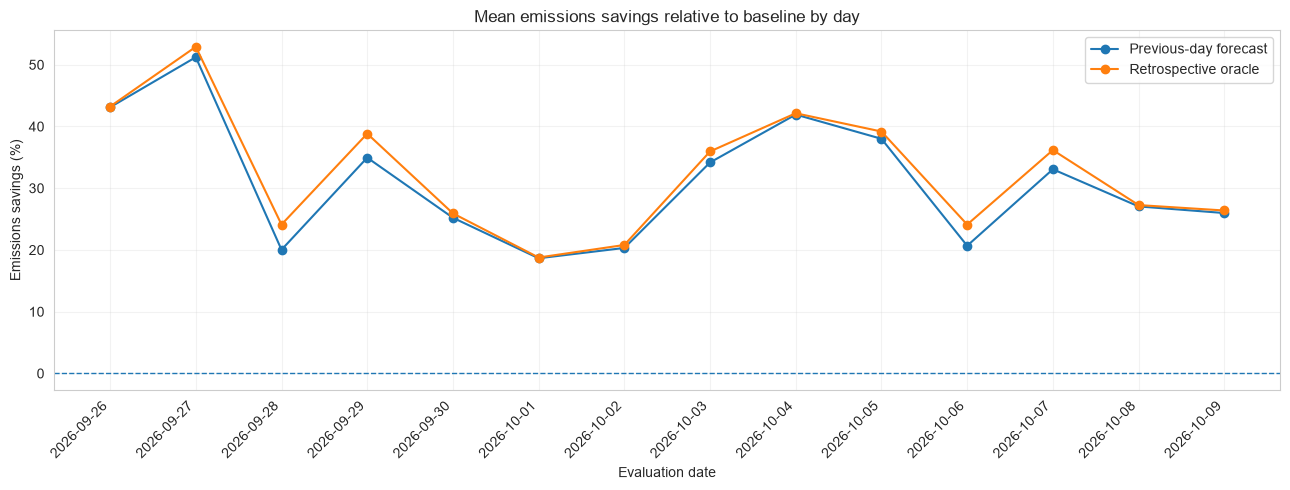

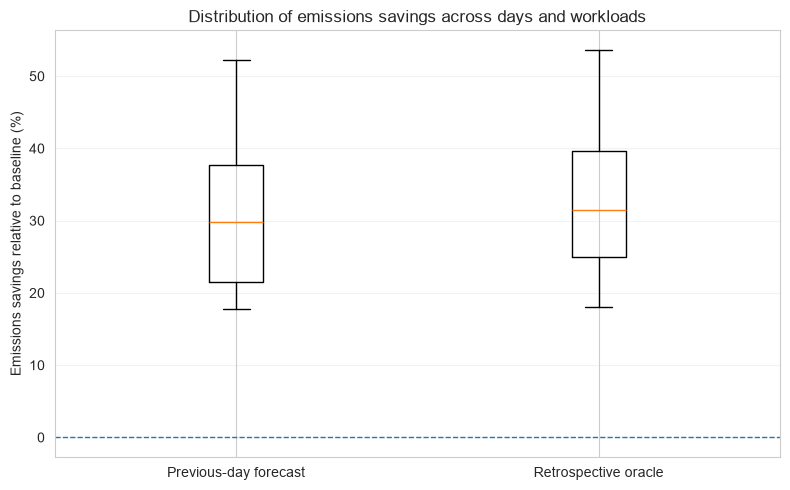

In [215]:
eligible_date_set = set(complete_days)
forecast_eligible_dates = [
    d for d in complete_days
    if previous_calendar_day(d) in eligible_date_set
]
selected_dates = forecast_eligible_dates[-N_DAYS_EVALUATION:]
if not selected_dates:
    raise ValueError("No evaluation dates have both a complete current-day and previous-day CI profile.")

print(f"Evaluation dates ({len(selected_dates)}): {selected_dates[0]} through {selected_dates[-1]}")
experiment_rows = []

for date_string in selected_dates:
    actual_ci = get_complete_day_ci(date_string)
    forecast_ci_day = get_complete_day_ci(previous_calendar_day(date_string))
    for seed in WORKLOAD_SEEDS:
        scenario_tasks = generate_workload(
            n_slots=len(actual_ci), n_jobs=N_JOBS, seed=int(seed)
        )
        scenario_baseline = schedule_earliest_feasible(
            scenario_tasks, len(actual_ci), P_MAX_KW, MAX_CONCURRENT_JOBS
        )
        scenario_forecast = optimize_schedule_milp(
            scenario_tasks, forecast_ci_day, P_MAX_KW, MAX_CONCURRENT_JOBS
        )
        scenario_oracle = optimize_schedule_milp(
            scenario_tasks, actual_ci, P_MAX_KW, MAX_CONCURRENT_JOBS
        )

        scenario_policies = {
            "Carbon-unaware baseline": scenario_baseline,
            "Previous-day forecast": scenario_forecast,
            "Retrospective oracle": scenario_oracle,
        }
        baseline_emissions_scenario = None
        scenario_metrics = {}
        for policy_name, start_map in scenario_policies.items():
            metrics, _, _, _ = evaluate_schedule(
                scenario_tasks, start_map, actual_ci, P_MAX_KW, MAX_CONCURRENT_JOBS
            )
            scenario_metrics[policy_name] = metrics
            if policy_name == "Carbon-unaware baseline":
                baseline_emissions_scenario = metrics["emissions_kgCO2eq"]

        for policy_name, metrics in scenario_metrics.items():
            base_emissions = float(baseline_emissions_scenario)
            saving_kg = base_emissions - metrics["emissions_kgCO2eq"]
            saving_pct = 100.0 * saving_kg / base_emissions if base_emissions else np.nan
            experiment_rows.append({
                "date": date_string,
                "workload_seed": int(seed),
                "n_jobs": N_JOBS,
                "p_max_kw": P_MAX_KW,
                "max_concurrent_jobs": MAX_CONCURRENT_JOBS,
                "policy": policy_name,
                **metrics,
                "emissions_savings_vs_baseline_kg": saving_kg,
                "emissions_savings_vs_baseline_pct": saving_pct,
            })

experiment_results = pd.DataFrame(experiment_rows)
print(f"Completed {len(selected_dates) * len(WORKLOAD_SEEDS)} date/workload scenarios.")
print("Aggregate results by policy:")
experiment_summary = (
    experiment_results.groupby("policy")
    .agg(
        scenarios=("date", "count"),
        mean_emissions_kgCO2eq=("emissions_kgCO2eq", "mean"),
        median_emissions_kgCO2eq=("emissions_kgCO2eq", "median"),
        mean_savings_kg=("emissions_savings_vs_baseline_kg", "mean"),
        mean_savings_pct=("emissions_savings_vs_baseline_pct", "mean"),
        std_savings_pct=("emissions_savings_vs_baseline_pct", "std"),
        mean_wait_hours=("mean_wait_hours", "mean"),
        mean_peak_power_kw=("peak_power_kw", "mean"),
        deadline_violations=("deadline_violations", "sum"),
    )
    .sort_index()
)
display(experiment_summary)

daily_savings = experiment_results.groupby(["date", "policy"])["emissions_savings_vs_baseline_pct"].mean().unstack("policy")
plt.figure(figsize=(13, 5))
for policy_name in ["Previous-day forecast", "Retrospective oracle"]:
    if policy_name in daily_savings.columns:
        plt.plot(daily_savings.index, daily_savings[policy_name], marker="o", label=policy_name)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Mean emissions savings relative to baseline by day")
plt.xlabel("Evaluation date")
plt.ylabel("Emissions savings (%)")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
box_values = [
    experiment_results.loc[experiment_results["policy"] == name, "emissions_savings_vs_baseline_pct"].to_numpy()
    for name in ["Previous-day forecast", "Retrospective oracle"]
]
plt.boxplot(box_values, tick_labels=["Previous-day forecast", "Retrospective oracle"])
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Distribution of emissions savings across days and workloads")
plt.ylabel("Emissions savings relative to baseline (%)")
plt.grid(True, axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Sensitivity analysis: change the power-capacity limit

Capacity is an important constraint: a tight limit can prevent jobs from occupying the lowest-carbon intervals simultaneously. The following experiment keeps the demo workload and date fixed but varies the aggregate power budget. Each policy is evaluated with the same capacity setting for a fair comparison.

In [216]:
capacity_values = [18.0, 22.0, 26.0]
sensitivity_rows = []

for cap in capacity_values:
    cap_baseline = schedule_earliest_feasible(tasks, len(demo_ci), cap, MAX_CONCURRENT_JOBS)
    cap_forecast = optimize_schedule_milp(tasks, forecast_ci, cap, MAX_CONCURRENT_JOBS)
    cap_oracle = optimize_schedule_milp(tasks, demo_ci, cap, MAX_CONCURRENT_JOBS)
    cap_policies = {
        "Carbon-unaware baseline": cap_baseline,
        "Previous-day forecast": cap_forecast,
        "Retrospective oracle": cap_oracle,
    }
    cap_metrics = {}
    for name, start_map in cap_policies.items():
        metrics, _, _, _ = evaluate_schedule(
            tasks, start_map, demo_ci, cap, MAX_CONCURRENT_JOBS
        )
        cap_metrics[name] = metrics
    cap_base_emissions = cap_metrics["Carbon-unaware baseline"]["emissions_kgCO2eq"]
    for name, metrics in cap_metrics.items():
        saving_kg = cap_base_emissions - metrics["emissions_kgCO2eq"]
        sensitivity_rows.append({
            "p_max_kw": cap,
            "policy": name,
            "energy_kwh": metrics["energy_kwh"],
            "emissions_kgCO2eq": metrics["emissions_kgCO2eq"],
            "savings_vs_baseline_kg": saving_kg,
            "savings_vs_baseline_pct": 100.0 * saving_kg / cap_base_emissions if cap_base_emissions else np.nan,
            "mean_wait_hours": metrics["mean_wait_hours"],
            "peak_power_kw": metrics["peak_power_kw"],
            "deadline_violations": metrics["deadline_violations"],
        })

capacity_results = pd.DataFrame(sensitivity_rows)
display(capacity_results.sort_values(["p_max_kw", "policy"]).reset_index(drop=True))

plt.figure(figsize=(9, 5))
for policy_name in ["Previous-day forecast", "Retrospective oracle"]:
    subset = capacity_results[capacity_results["policy"] == policy_name].sort_values("p_max_kw")
    plt.plot(subset["p_max_kw"], subset["savings_vs_baseline_pct"], marker="o", label=policy_name)
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Carbon savings sensitivity to aggregate power capacity")
plt.xlabel("Power capacity (kW)")
plt.ylabel("Emissions savings relative to same-capacity baseline (%)")
plt.legend()
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

ValueError: The earliest-feasible baseline could not schedule J101 within its deadline. Try reducing the workload or increasing capacity.

## 11. Export results and produce a concise interpretation

The following cell writes portable CSV outputs to `carbon_scheduling_outputs/` in the notebook's current working directory. These files make it easier to inspect results outside Jupyter or reuse them in a report.

In [ ]:
#OUTPUT_DIR = Path("carbon_scheduling_outputs")
#OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
#
## The synthetic workload and the three schedules for the demo day.
#tasks.to_csv(OUTPUT_DIR / "demo_workload.csv", index=False)
#demo_metrics.reset_index().to_csv(OUTPUT_DIR / "demo_policy_metrics.csv", index=False)
#
#schedule_export_frames = []
#for policy_name, schedule_table in policy_schedules.items():
#    schedule_export = add_clock_labels(schedule_table)
#    schedule_export.insert(0, "policy", policy_name)
#    schedule_export.insert(1, "date", DEMO_DATE)
#    schedule_export_frames.append(schedule_export)
#pd.concat(schedule_export_frames, ignore_index=True).to_csv(
#    OUTPUT_DIR / "demo_schedules.csv", index=False
#)
#
#experiment_results.to_csv(OUTPUT_DIR / "multi_day_experiment_results.csv", index=False)
#experiment_summary.reset_index().to_csv(OUTPUT_DIR / "multi_day_experiment_summary.csv", index=False)
#capacity_results.to_csv(OUTPUT_DIR / "capacity_sensitivity_results.csv", index=False)
#day_stats.to_csv(OUTPUT_DIR / "daily_carbon_coverage.csv", index=False)
#
#print(f"CSV outputs saved to: {OUTPUT_DIR.resolve()}")
#for file_path in sorted(OUTPUT_DIR.glob("*.csv")):
#    print(f"- {file_path.name} ({file_path.stat().st_size:,} bytes)")
#
## Core sanity checks for the detailed comparison.
#assert len(baseline_starts) == len(tasks) == len(forecast_starts) == len(oracle_starts)
#assert np.isclose(
#    policy_metrics["Carbon-unaware baseline"]["energy_kwh"],
#    policy_metrics["Previous-day forecast"]["energy_kwh"],
#)
#assert np.isclose(
#    policy_metrics["Carbon-unaware baseline"]["energy_kwh"],
#    policy_metrics["Retrospective oracle"]["energy_kwh"],
#)
#assert experiment_results["deadline_violations"].sum() == 0
#print("All final sanity checks passed.")

## 12. How to interpret the outcomes

Use the tables and plots to answer the following research questions:

1. **Does temporal shifting reduce estimated emissions?** Compare each policy's emissions and percentage savings against the same-capacity baseline.
2. **How much does forecast error matter?** Compare the previous-day forecast policy against the retrospective oracle. The gap indicates the value of better carbon-intensity forecasts for these workloads, under this particular forecast proxy.
3. **What is the capacity trade-off?** Observe how power limits influence achievable savings, peak load, and average waiting time.
4. **Are SLA constraints respected?** Deadline, release-time, power-capacity, and concurrency violations should all remain zero for accepted schedules.
5. **Is the effect robust across days and workloads?** Use the multi-day distribution, not a single day's best result, to report means, medians, and variability.

### Limitations to state in a thesis

- Synthetic jobs do not represent measured cloud workloads; vary job counts, durations, power demand, and deadlines in further experiments.
- The data signal is an estimated average lifecycle carbon intensity. It is not a direct estimate of marginal emissions avoided.
- The oracle uses perfect future knowledge and is only an offline upper-bound benchmark.
- The previous-day trace is a deliberately simple forecast proxy. A stronger study should train and evaluate a forecasting model with a chronological train/test split, then feed genuinely out-of-sample forecasts to the scheduler.
- The MILP uses a 5-second time limit and a 1% relative gap target to keep multi-day experiments practical. If a time limit is reached, the feasible incumbent is not guaranteed to be a proven global optimum; inspect solver warnings and tighten settings for final experiments.
- This version models one region and temporal shifting only. Spatial scheduling would require equivalent traces for other regions plus network-transfer energy, latency, regional capacity, and migration constraints.
- The cloud power profile is simplified: tasks have constant power, and idle/server overhead, DVFS, memory constraints, cooling, startup costs, and task migration are not modeled.

**Recommended reporting practice:** report the dataset coverage dates, workload-generation parameters, capacity assumptions, optimization solver and status, mean/median savings, variability across scenarios, and all SLA/resource violations. Do not report the oracle result as a deployable forecast-based saving.